In [1]:
import pandas as pd
import numpy as np
import json
from config import *
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Main Model

In [23]:
rows=[]

for filename in os.listdir(outpath):
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)
        
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append({
                        "name": name,
                        "representation": filename[:-5],
                        "model": model,
                        "metric": metric,
                        "value": value
                    })

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,representation,model,metric,value
0,BD135193,GC_count,RF,roc_auc,0.620370
1,BD135193,GC_count,RF,pr_auc,0.752758
2,BD135193,GC_count,RF,precision,0.615385
3,BD135193,GC_count,RF,recall,1.000000
4,BD135193,GC_count,RF,fscore,0.761905
...,...,...,...,...,...
6745,XM_371822,atomic_number,DT,roc_auc,0.669540
6746,XM_371822,atomic_number,DT,pr_auc,0.519485
6747,XM_371822,atomic_number,DT,precision,0.587302
6748,XM_371822,atomic_number,DT,recall,0.637931


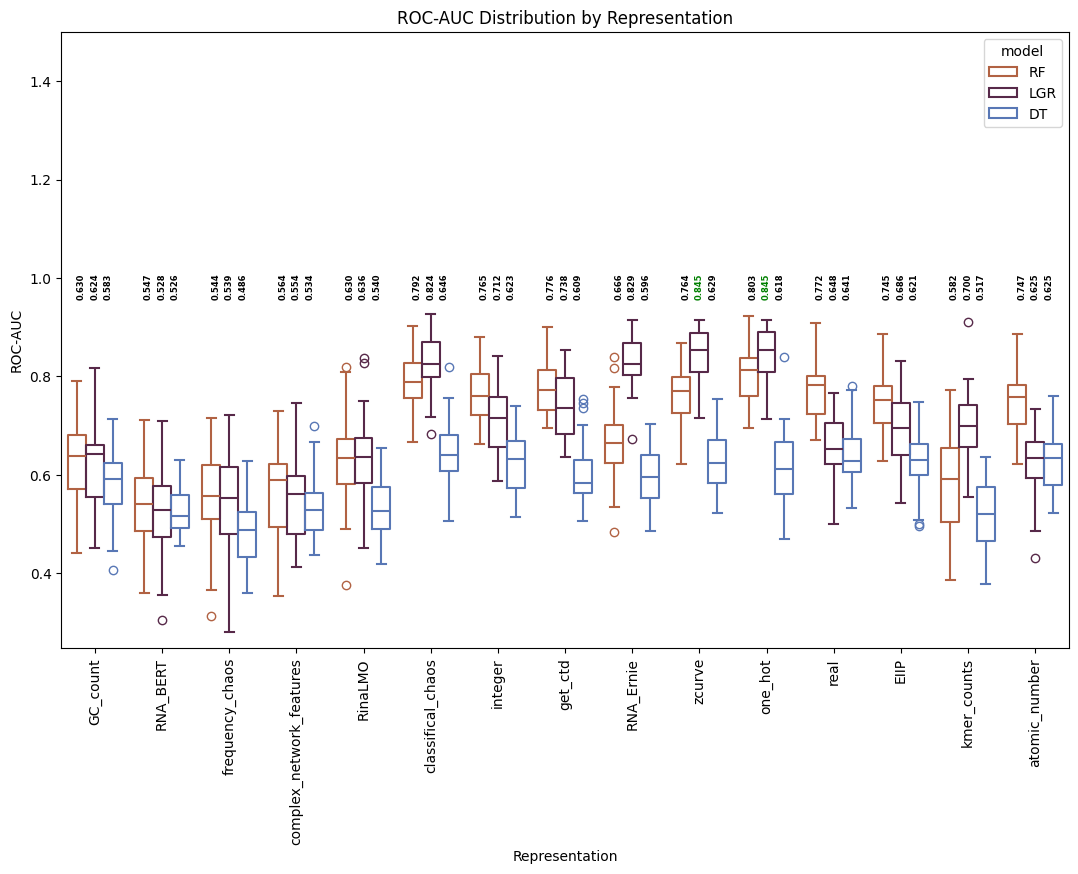

In [63]:
df_auc = df[df["metric"] == "roc_auc"]

plt.figure(figsize=(13,8))
sns.boxplot(x="representation", y="value", data=df_auc, hue='model', palette='managua',fill=False)
plt.ylabel("ROC-AUC")
plt.xlabel("Representation")
plt.ylim(top=1.5)
plt.title("ROC-AUC Distribution by Representation")
plt.xticks(rotation=90)
box_positions={}
avg_vals = df_auc.groupby(["representation", "model"])["value"].mean().reset_index()
y_max = df_auc["value"].max()
# Get positions of the boxes
models = df_auc["model"].unique()
for i, rep in enumerate(df_auc["representation"].unique()):
    for j, model in enumerate(models):
        box_positions[(rep, model)] = i + (j - (len(models)-1)/2) * 0.2  # adjust for hue width
        
max_val = round(avg_vals["value"].max(), 3)
# Annotate means at the top (same height for all)
for _, row in avg_vals.iterrows():
    pos = box_positions[(row["representation"], row["model"])]
    color = "green" if round(row["value"],3) == max_val else "black"
    plt.text(pos, y_max + 0.03, f"{row['value']:.3f}",
             ha='center', va='bottom', fontsize=6, fontweight="bold", color=color, rotation=90)

plt.savefig('ROC-AUC.png',dpi=300)


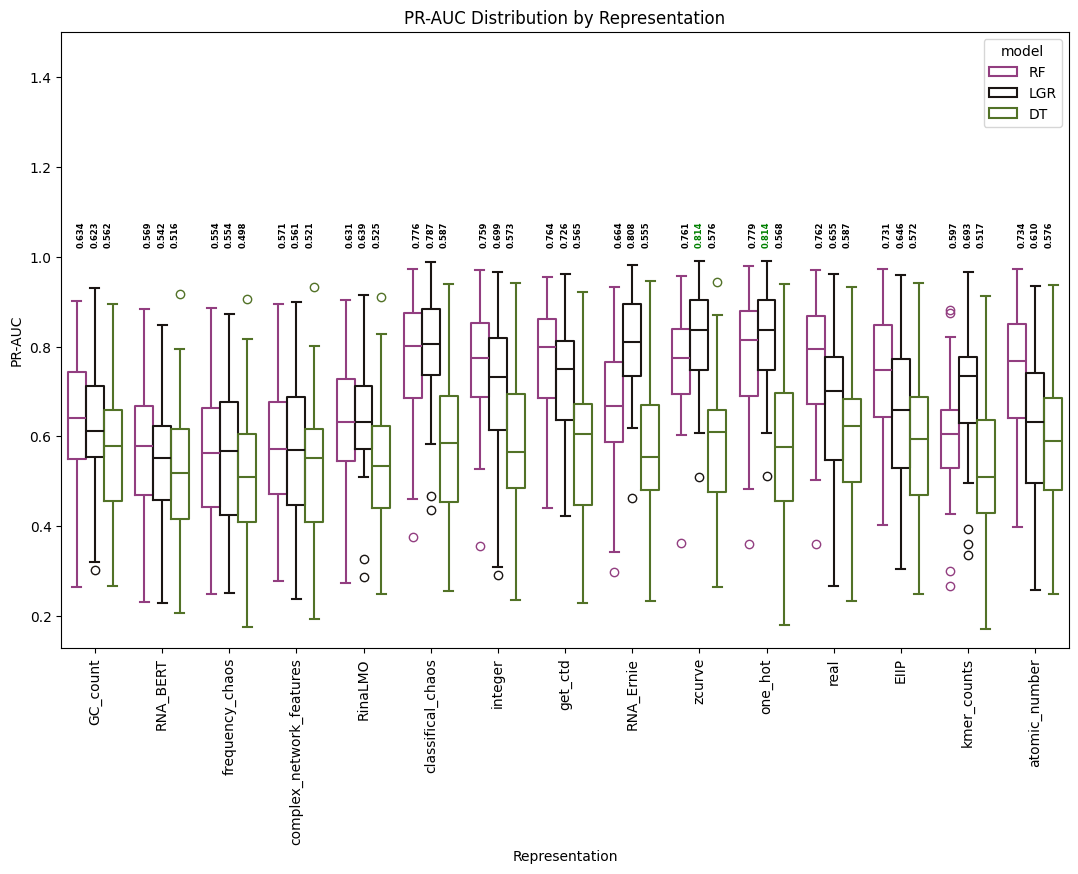

In [62]:
df_auc = df[df["metric"] == "pr_auc"]

plt.figure(figsize=(13,8))
sns.boxplot(x="representation", y="value", data=df_auc, hue='model', palette='vanimo',fill=False)
plt.ylabel("PR-AUC")
plt.xlabel("Representation")
plt.title("PR-AUC Distribution by Representation")
plt.xticks(rotation=90)
box_positions={}
avg_vals = df_auc.groupby(["representation", "model"])["value"].mean().reset_index()
y_max = df_auc["value"].max()
# Get positions of the boxes
models = df_auc["model"].unique()
for i, rep in enumerate(df_auc["representation"].unique()):
    for j, model in enumerate(models):
        box_positions[(rep, model)] = i + (j - (len(models)-1)/2) * 0.2  # adjust for hue width
        
max_val = round(avg_vals["value"].max(), 3)
# Annotate means at the top (same height for all)
for _, row in avg_vals.iterrows():
    pos = box_positions[(row["representation"], row["model"])]
    color = "green" if round(row["value"],3) == max_val else "black"
    plt.text(pos, y_max + 0.03, f"{row['value']:.3f}",
             ha='center', va='bottom', fontsize=6, fontweight="bold", color=color, rotation=90)


plt.ylim(top=1.5)
plt.savefig('PR-AUC.png',dpi=300)


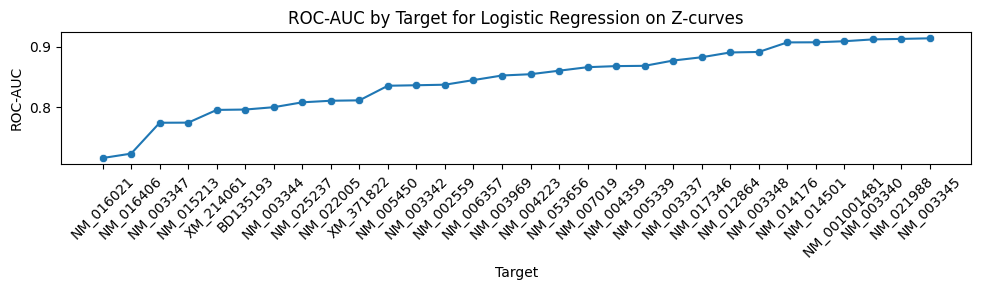

In [65]:
filtered_df = df[(df['model'] == 'LGR') & 
                 (df['representation'] == 'zcurve') & 
                 (df['metric'] == 'roc_auc')]

# Sort by value ascending
filtered_df = filtered_df.sort_values(by='value')

# Scatter line plot
plt.figure(figsize=(10,3))
sns.scatterplot(data=filtered_df, x='name', y='value')
sns.lineplot(data=filtered_df, x='name', y='value', sort=False)

plt.xticks(rotation=45)
plt.xlabel('Target')
plt.ylabel('ROC-AUC')
plt.title('ROC-AUC by Target for Logistic Regression on Z-curves')
plt.tight_layout()
plt.savefig('LGR_ZCURVE_ROC.png',dpi=300)

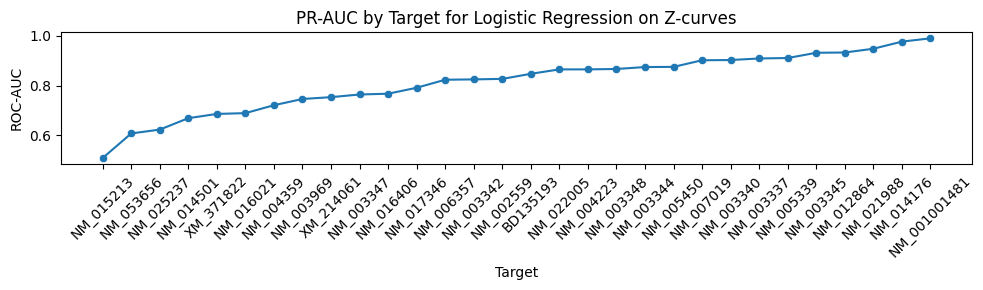

In [66]:
filtered_df = df[(df['model'] == 'LGR') & 
                 (df['representation'] == 'zcurve') & 
                 (df['metric'] == 'pr_auc')]

# Sort by value ascending
filtered_df = filtered_df.sort_values(by='value')

# Scatter line plot
plt.figure(figsize=(10,3))
sns.scatterplot(data=filtered_df, x='name', y='value')
sns.lineplot(data=filtered_df, x='name', y='value', sort=False)

plt.xticks(rotation=45)
plt.xlabel('Target')
plt.ylabel('ROC-AUC')
plt.title('PR-AUC by Target for Logistic Regression on Z-curves')
plt.tight_layout()
plt.savefig('LGR_ZCURVE_PR.png',dpi=300)

# Sliding Window

In [13]:
rows=[]

for filename in ['zcurve_'+str(i)+'.json' for i in range(0,21)]:
    if filename.endswith(".json"):  # process only JSON files
        filepath = os.path.join(outpath, filename)
        
        with open(filepath, "r", encoding="utf-8") as f:
            data = json.load(f)

        # Ignore "run name" key
        for name, models in data.items():
            if name == "representations":
                continue  # skip this key

            for model, metrics in models.items():
                for metric, value in metrics.items():
                    rows.append({
                        "name": name,
                        "window": filename[:-5],
                        "model": model,
                        "metric": metric,
                        "value": value
                    })

# Build DataFrame
df = pd.DataFrame(rows)

df

,name,window,model,metric,value
0,BD135193,zcurve_0,RF,roc_auc,0.814815
1,BD135193,zcurve_0,RF,pr_auc,0.842395
2,BD135193,zcurve_0,RF,precision,0.785714
3,BD135193,zcurve_0,RF,recall,0.825000
4,BD135193,zcurve_0,RF,fscore,0.804878
...,...,...,...,...,...
9445,XM_371822,zcurve_20,DT,roc_auc,0.528835
9446,XM_371822,zcurve_20,DT,pr_auc,0.413430
9447,XM_371822,zcurve_20,DT,precision,0.407895
9448,XM_371822,zcurve_20,DT,recall,0.534483


/tmp/ipykernel_348132/335203527.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="window", y="value", data=df_auc, palette='managua',fill=False)


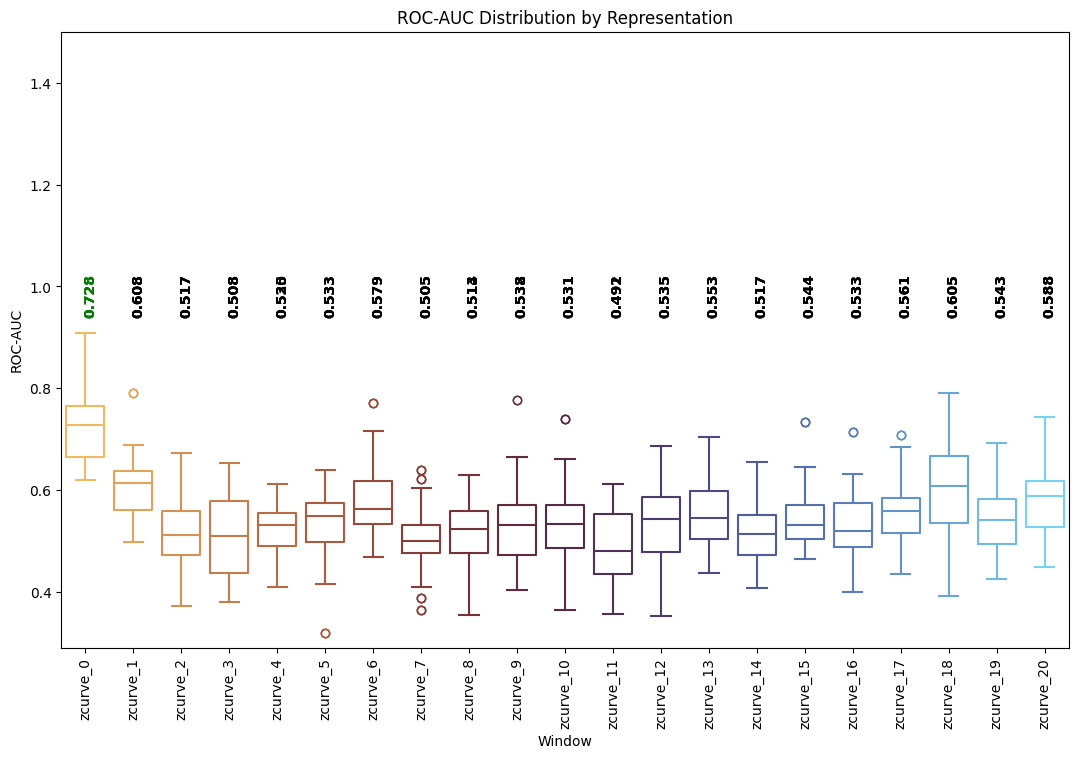

In [15]:
df_auc = df[df["metric"] == "roc_auc"]

plt.figure(figsize=(13,8))
sns.boxplot(x="window", y="value", data=df_auc, palette='managua',fill=False)
plt.ylabel("ROC-AUC")
plt.xlabel("Window")
plt.ylim(top=1.5)
plt.title("ROC-AUC Distribution by Representation")
plt.xticks(rotation=90)
box_positions={}
avg_vals = df_auc.groupby(["window", "model"])["value"].mean().reset_index()
y_max = df_auc["value"].max()
# Get positions of the boxes

for i, rep in enumerate(df_auc["window"].unique()):
        box_positions[(rep)] = i + ((1)/2) * 0.2  # adjust for hue width
        
max_val = round(avg_vals["value"].max(), 3)
# Annotate means at the top (same height for all)
for _, row in avg_vals.iterrows():
    pos = box_positions[(row["window"])]
    color = "green" if round(row["value"],3) == max_val else "black"
    plt.text(pos, y_max + 0.03, f"{row['value']:.3f}",
             ha='center', va='bottom', fontsize=10, fontweight="bold", color=color, rotation=90)

plt.savefig('ROC-AUC_Sliding.png',dpi=300)
